# Plot global gradients of main principal components 

In [1]:
!pwd



/net/home/swolf/Func_Neo_Phytes/notebooks/final_notebooks


In [2]:
# set working directory
import os
os.chdir("/net/home/swolf/Func_Neo_Phytes/")

### Load summary stats at hexagon level

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import h3pandas

In [4]:
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv")## PREPRINT VERSION

summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv")
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,...,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
0,83831efffffffff,4.791148,3.776629,0.972105,1.108890,-0.543161,-0.344312,-0.421365,1.020680,0.577483,...,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
1,838218fffffffff,3.901431,5.058331,1.130704,0.513898,-0.246278,0.057208,-0.472530,-0.547894,0.295538,...,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
2,838233fffffffff,5.296893,7.964621,0.734479,0.175995,-0.373005,0.697346,-1.405497,-1.565001,1.315280,...,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
3,838230fffffffff,5.160745,6.437678,1.152159,0.761990,-0.937332,-0.018926,0.092611,0.814618,0.881475,...,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
4,83be4dfffffffff,0.601728,0.684375,-7.733539,-7.925340,2.775503,2.866219,0.476081,0.466763,-0.687836,...,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3


### Calculate percentage naturalized


In [5]:
# Add a new column 'ratio' as the fraction of 'column1' and 'column2'

summary_data['perc_naturalized'] = (summary_data['count_all'] - summary_data['count_native']) / summary_data['count_all']*100

In [6]:
summary_data['perc_naturalized_sp'] = (summary_data['count_sp_all'] - summary_data['count_sp_native']) / summary_data['count_sp_all']*100

In [7]:
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,...,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution,perc_naturalized,perc_naturalized_sp
0,83831efffffffff,4.791148,3.776629,0.972105,1.108890,-0.543161,-0.344312,-0.421365,1.020680,0.577483,...,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3,44.000000,46.575342
1,838218fffffffff,3.901431,5.058331,1.130704,0.513898,-0.246278,0.057208,-0.472530,-0.547894,0.295538,...,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3,23.684211,17.857143
2,838233fffffffff,5.296893,7.964621,0.734479,0.175995,-0.373005,0.697346,-1.405497,-1.565001,1.315280,...,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3,46.666667,42.857143
3,838230fffffffff,5.160745,6.437678,1.152159,0.761990,-0.937332,-0.018926,0.092611,0.814618,0.881475,...,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3,42.857143,46.428571
4,83be4dfffffffff,0.601728,0.684375,-7.733539,-7.925340,2.775503,2.866219,0.476081,0.466763,-0.687836,...,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3,1.971073,26.062847


In [8]:
# add column with count_all and count_native in ln scale
import numpy as np

summary_data['log_count_all'] = np.log10(summary_data['count_all'])
summary_data['log_count_native'] = np.log10(summary_data['count_native'])


summary_data['log_count_all_sp'] = np.log10(summary_data['count_sp_all'])
summary_data['log_count_native_sp'] = np.log10(summary_data['count_sp_native'])

In [9]:

summary_data['count_non_native'] = summary_data['count_sp_all'] - summary_data['count_sp_native']
summary_data['log_count_non_native'] = np.log10(summary_data['count_non_native'])

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [10]:
# calculate differences between native and all for PC1 and PC2
summary_data['PC1_diff'] = summary_data['PC1_all'] - summary_data['PC1_native']
summary_data['PC2_diff'] = summary_data['PC2_all'] - summary_data['PC2_native']
summary_data['PC3_diff'] = summary_data['PC3_all'] - summary_data['PC3_native']
summary_data['PC4_diff'] = summary_data['PC4_all'] - summary_data['PC4_native']
summary_data['PC5_diff'] = summary_data['PC5_all'] - summary_data['PC5_native']



## Map hexagons

### Create GeoDataFrame and Clean Geometries

This code block converts H3 hexagon indices to polygons, wraps longitudes to the range [-180, 180], and creates a GeoDataFrame. Invalid geometries and polygons spanning more than 180° longitude are removed to ensure clean and accurate spatial data for further analysis.




In [11]:
final_df = summary_data.copy()

In [12]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon
from shapely.ops import transform
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Function to convert H3 cell to polygon
def h3_to_polygon(h3_index):
    boundary = h3.h3_to_geo_boundary(h3_index, geo_json=True)
    return Polygon(boundary)

# Function to wrap longitudes to [-180, 180]
def wrap_geometry(geom):
    def wrap_coords(x, y):
        x_wrapped = ((x + 180) % 360) - 180
        return x_wrapped, y
    return transform(lambda x, y: wrap_coords(x, y), geom)

# Build geometry column
final_df["geometry"] = final_df["h3_res3"].apply(lambda x: wrap_geometry(h3_to_polygon(x)))

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(final_df, geometry="geometry", crs="EPSG:4326")

# Fix column names
gdf.columns = gdf.columns.str.replace('.', '_')

# 💥 Remove invalid geometries and those spanning too much longitude
gdf = gdf[gdf.geometry.is_valid]  # remove invalid
gdf = gdf[gdf.bounds.maxx - gdf.bounds.minx < 180]  # remove polygons >180° wide


/tmp/ipykernel_95038/3219989185.py:28: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  gdf.columns = gdf.columns.str.replace('.', '_')


### Plot world map 

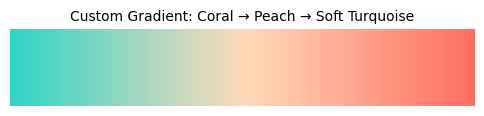

In [13]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Define your custom colors
colors = [ "#2ed5c9", "#FFDAB9", "#FF6F61"]

# Create the colormap
native_non_cmap = mcolors.LinearSegmentedColormap.from_list("custom_gradient", colors)

# OPTIONAL: Visualize it with a gradient bar
gradient = np.linspace(0, 1, 256).reshape(1, -1)

plt.figure(figsize=(6, 1))

plt.imshow(gradient, aspect='auto', cmap=native_non_cmap)
plt.axis("off")
plt.title("Custom Gradient: Coral → Peach → Soft Turquoise", fontsize=10)
plt.show()


In [14]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Define your colors
low_color = "#2F86AC"      # like native_color
mid_color = "white"
high_color = "#b02f2c"     # like all_color

# Create a custom diverging colormap
div_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_diverging",
    [low_color, mid_color, high_color]
)


In [15]:
def plot_maps(gdf, pattern, output_suffix="meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted"):
    
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    os.makedirs("Results/Figures", exist_ok=True)

    # Loop over columns matching the pattern
    for column in [col for col in gdf.columns if col.startswith(pattern)]:

        # -------------------------
        # Set colour scale
        # -------------------------

        if "percent_change" in column:
            vmin, vmax = -80, 80
            cmap = div_cmap

        elif "rank_biserial_r" in column:
            vmin, vmax = -0.7, 0.7
            cmap = div_cmap

        elif "perc_naturalized" in column:
            vmin, vmax = 0, 100
            cmap = "YlGnBu"

        elif "conifer_percentage" in column:
            vmin, vmax = 0, 20
            cmap = "YlGnBu"

        elif "annual_percentage" in column:
            vmin, vmax = 0, 40
            cmap = "YlGnBu_r"

        elif "PC1_diff" in column:
            vmin = np.nanpercentile(gdf[column], 5)
            vmax = np.nanpercentile(gdf[column], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC2_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC3_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC4_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC5_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif any(x in column for x in ["urban_diff", "nat_diff", "crop_diff"]):
            vmin, vmax = -1, 1
            cmap = div_cmap

        else:
            vmin = np.nanpercentile(gdf[column], 1)
            vmax = np.nanpercentile(gdf[column], 99)
            cmap = "YlGnBu"

        # -------------------------
        # Create map
        # -------------------------

        fig, ax = plt.subplots(
            figsize=(12, 10),
            subplot_kw={"projection": ccrs.EqualEarth()}
        )

        ax.set_global()

        ax.add_feature(
            cfeature.LAND,
            facecolor="#afafafff",
            edgecolor="none"
        )

        ax.add_feature(
            cfeature.OCEAN,
            facecolor="#dad8eaff",
            edgecolor="none"
        )

        ax._autoscaleXon = True
        ax._autoscaleYon = True

        # Plot hexagons
        gdf.plot(
            column=column,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            legend=True,
            ax=ax,
            transform=ccrs.PlateCarree(),
            linewidth=0.001,
            legend_kwds={"shrink": 0.45}
        )

        ax.set_title(
            f"{column} per hexagon",
            fontsize=12
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("#dad8eaff")
            spine.set_linewidth(0.7)

        plt.tight_layout()

        # -------------------------
        # Save
        # -------------------------

        output_path = (
            f"Results/Figures/"
            f"{column}_{output_suffix}.png"
        )

        plt.savefig(
            output_path,
            dpi=500,
            bbox_inches="tight"
        )
        print(output_path)
        plt.show()
        plt.close()

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/PC1_all_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


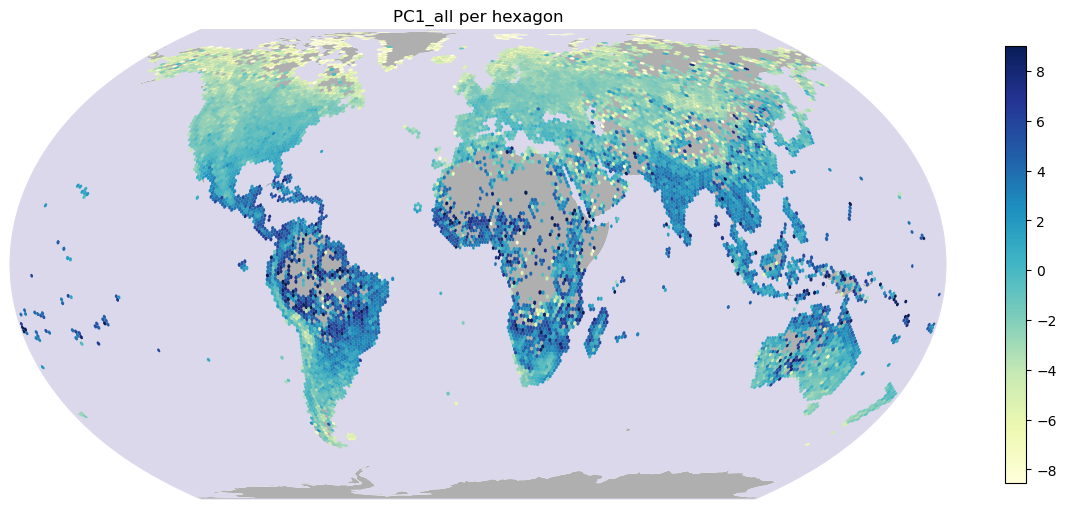

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC1_native_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


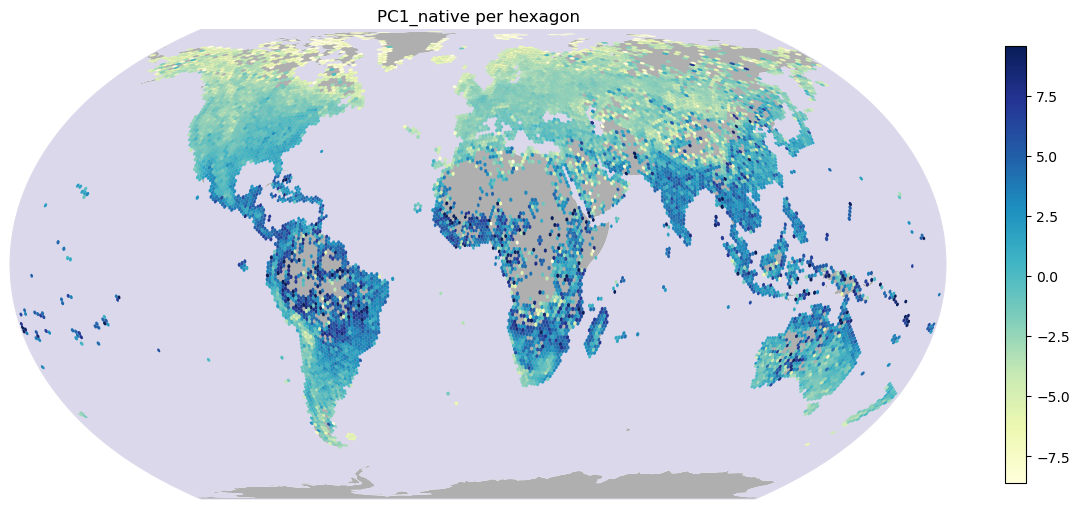

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC2_all_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


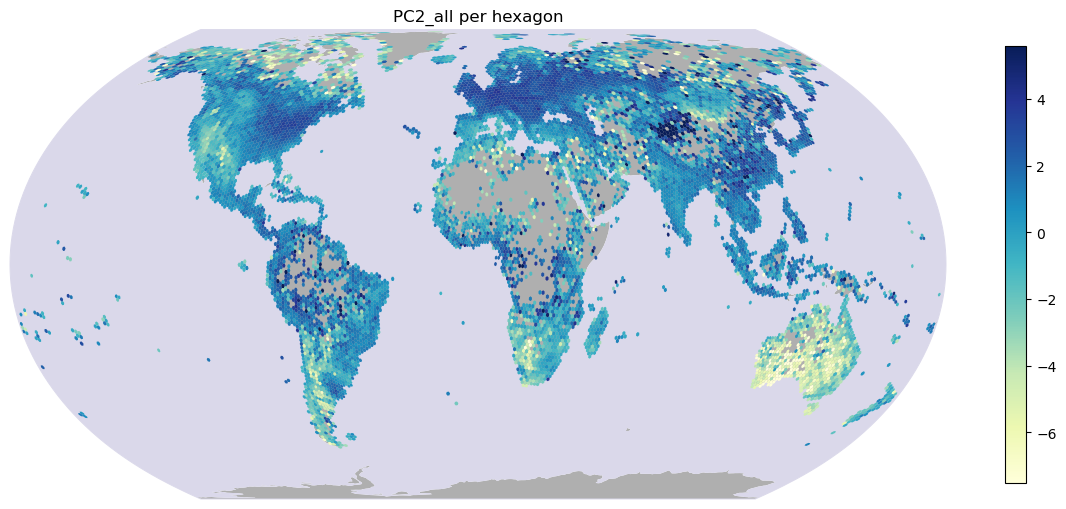

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC2_native_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


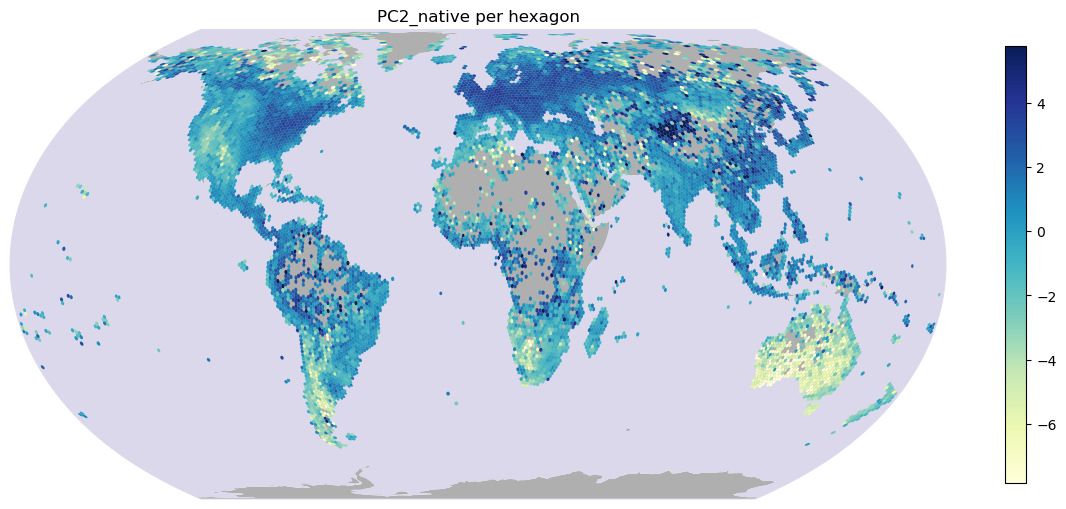

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC3_all_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


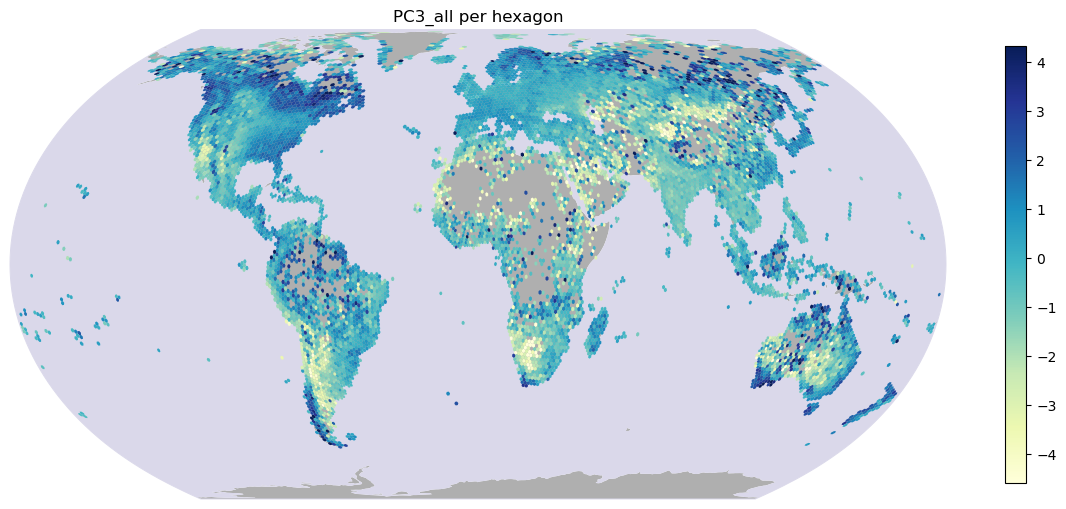

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC3_native_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


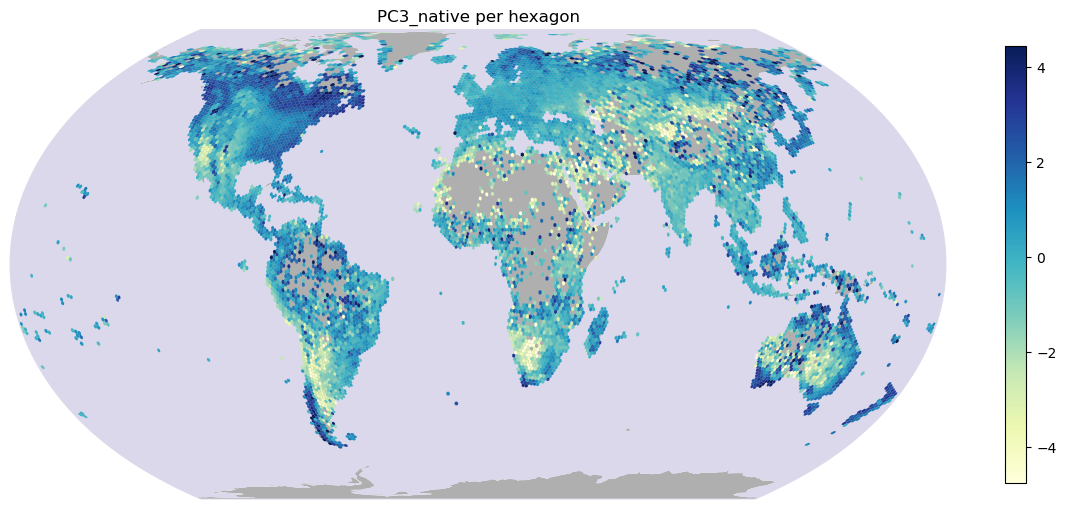

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC4_all_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


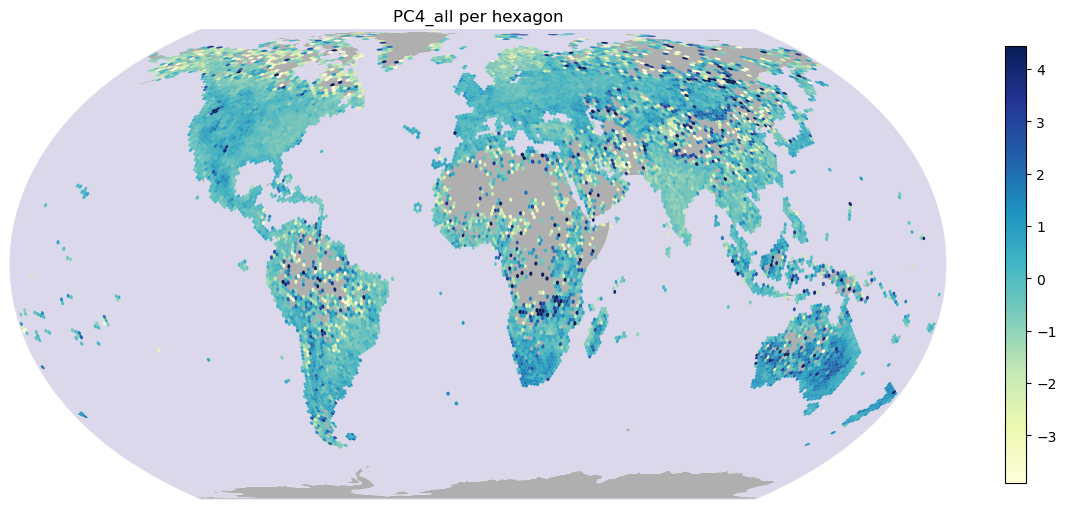

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC4_native_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


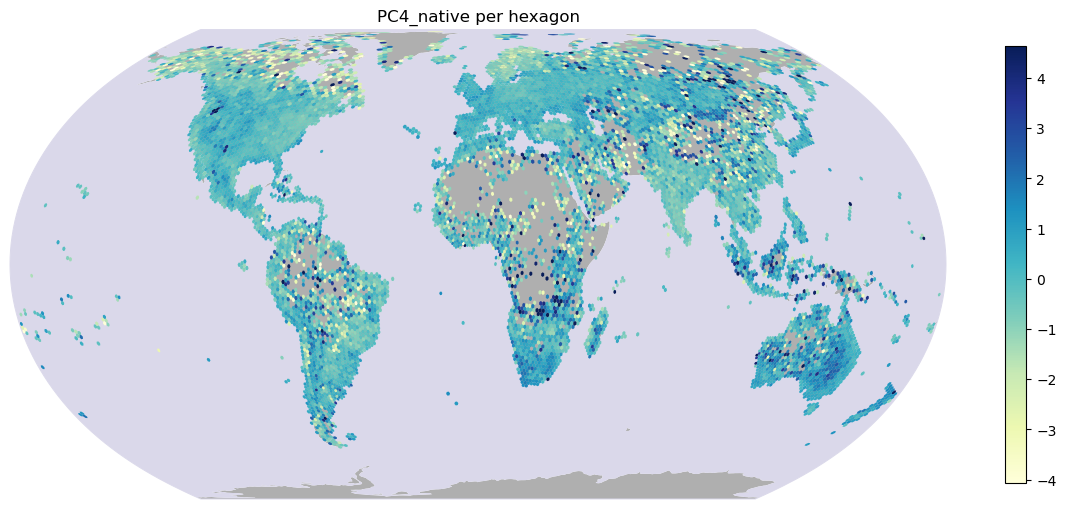

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC5_all_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


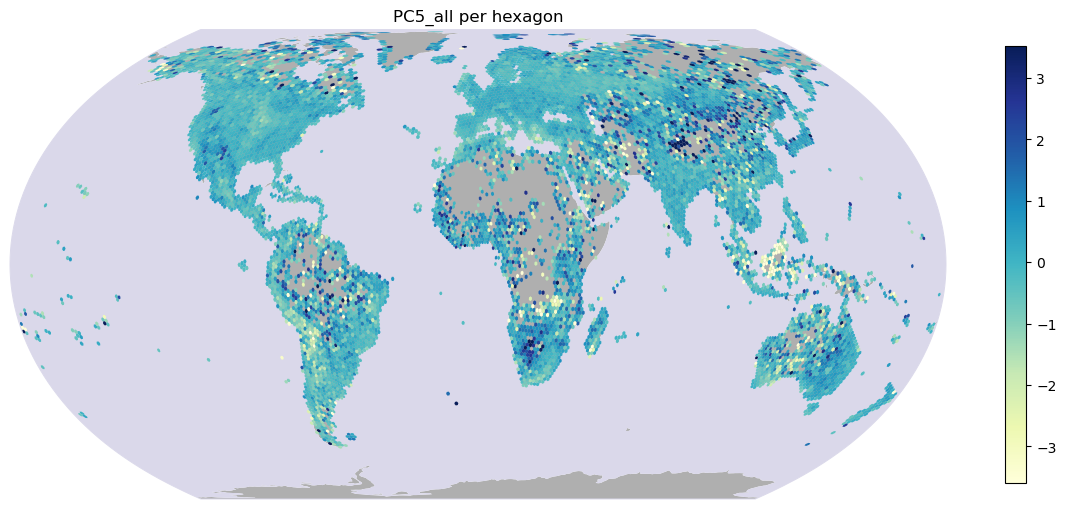

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC5_native_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


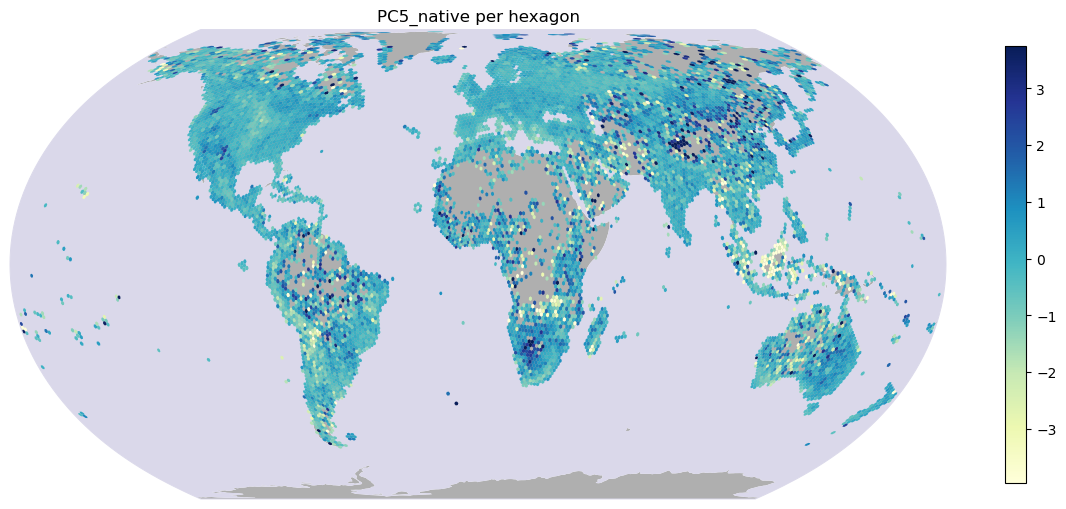

In [16]:
# Plot PC axes 1-5 for all and native

for pc in range(1, 6):
    for group in ("all", "native"):
        plot_maps(gdf, f"PC{pc}_{group}")

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC1_diff_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


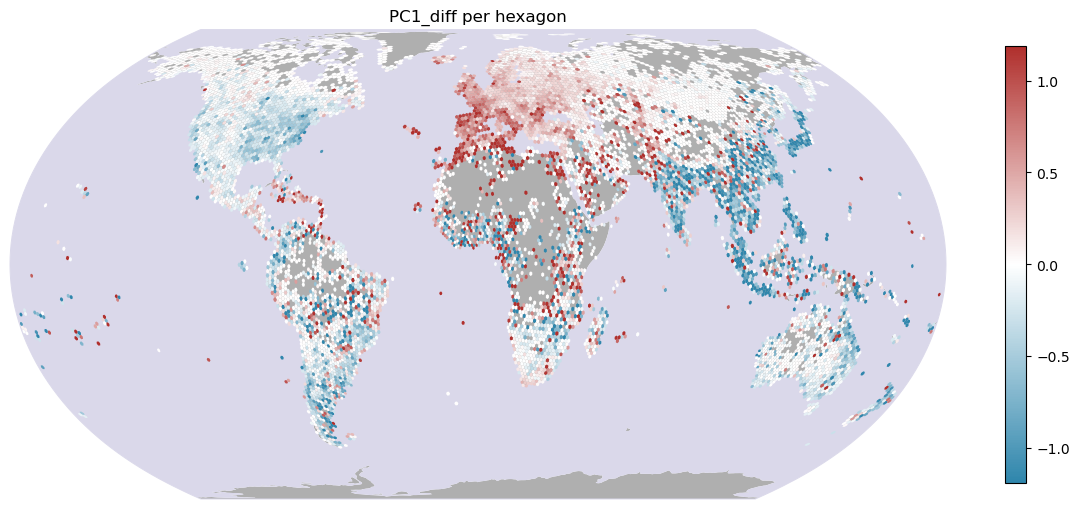

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC2_diff_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


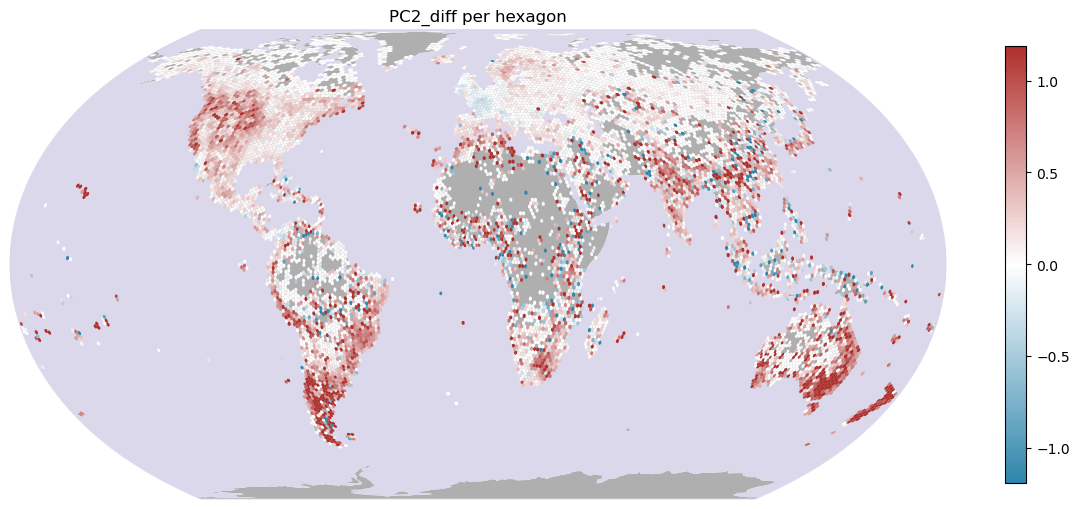

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC3_diff_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


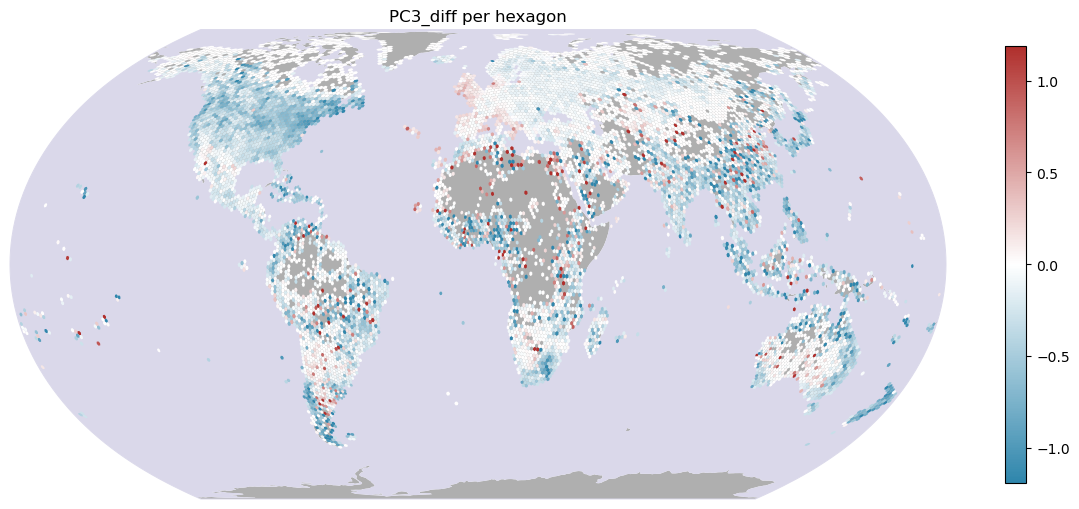

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC4_diff_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


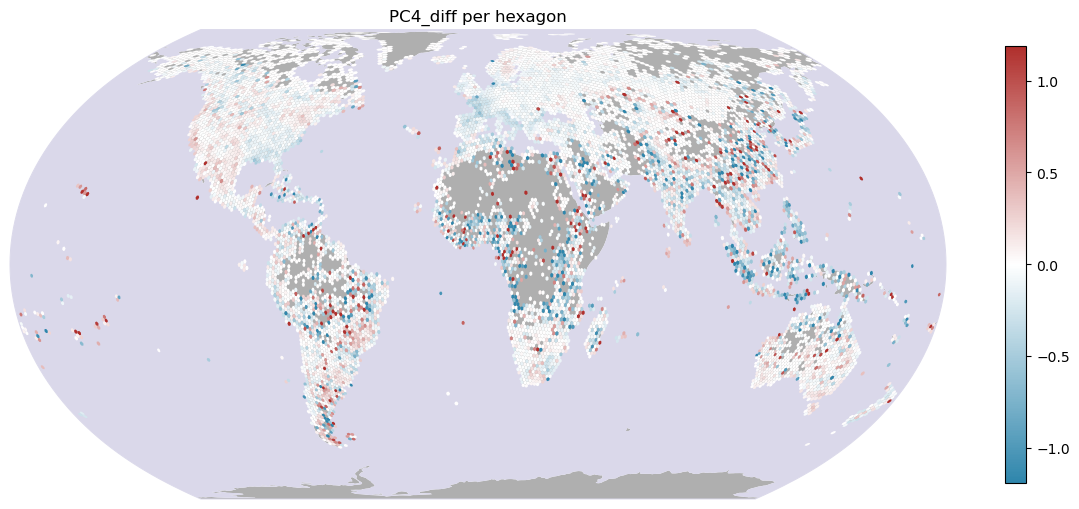

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC5_diff_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


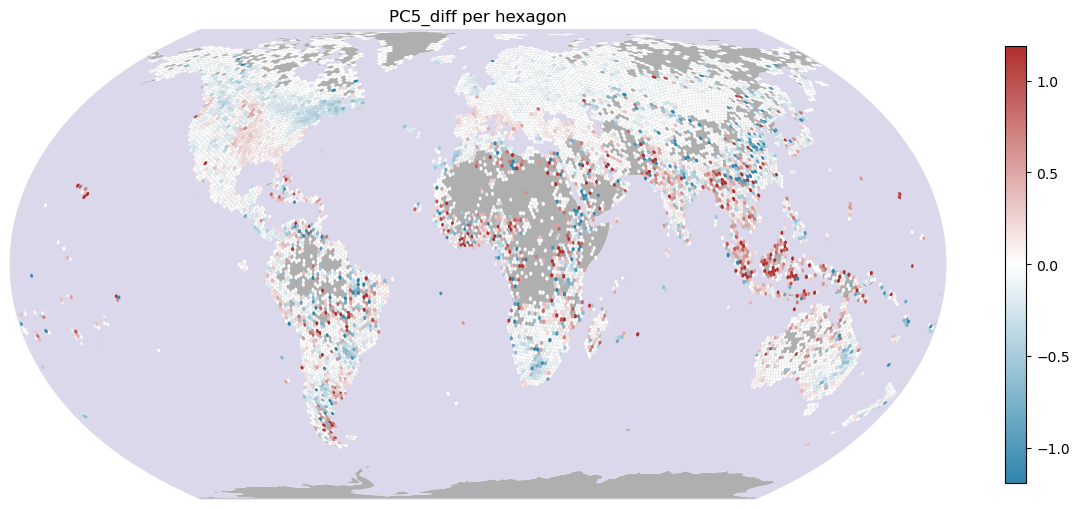

In [17]:
# Plot differeces in PC space for PC1, PC2, and PC3
plot_maps(gdf, "PC1_diff")
plot_maps(gdf, "PC2_diff")
plot_maps(gdf, "PC3_diff")
plot_maps(gdf, "PC4_diff")
plot_maps(gdf, "PC5_diff")